# 🧭 Codebase Onboarding Agent
Ask plain-English questions about any public **Python** GitHub repository. Covers both contest tracks: RAG over a Pinecone vector database, and a LangGraph agent.

**Before you run:** add `GOOGLE_API_KEY` and `PINECONE_API_KEY` to Colab **Secrets** 🔑 (optional: `UI_USERNAME`, `UI_PASSWORD`), then **Runtime → Run all**.

*Created as part of an assignment for Codecademy's Building Agentic AI Applications bootcamp, with Satyajit Pattnaik, Fall 2026.*

## 0 · Install

In [ ]:
# 0 Install packages (same versions as requirements.txt; Gradio is installed in section 12)
# google-genai<3 keeps Colab's preinstalled google-adk happy. Colab may still warn that
# google-colab wants an older google-auth: that warning is harmless and can be ignored.
!pip install -q "langchain>=1.0,<2" "langchain-google-genai>=4,<5" "google-genai>=2.20,<3" "langchain-pinecone>=0.2,<0.3" "langchain-text-splitters>=1,<2" "langgraph>=1,<2" "pinecone>=7,<8"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.


## 1 · API keys

In [ ]:
# 1 API keys: read from Colab Secrets, otherwise prompt
import os
from getpass import getpass

def load_secret(name: str) -> str:
    """Return a Colab secret, or prompt for it."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    return getpass(f"Enter your {name}: ")

def optional_secret(name: str):
    """Return a Colab secret or environment variable, or None. Never prompts."""
    try:
        from google.colab import userdata
        return userdata.get(name) or None
    except Exception:
        return os.environ.get(name) or None

os.environ["GOOGLE_API_KEY"] = load_secret("GOOGLE_API_KEY")
os.environ.pop("GEMINI_API_KEY", None)  # avoids duplicate-key warning
os.environ["PINECONE_API_KEY"] = load_secret("PINECONE_API_KEY")
print("✅ API keys loaded")

✅ API keys loaded


## 2 · Configuration

In [ ]:
# 2 Configuration

# Models
CHAT_MODEL = "gemini-3.8-flash"
# Tried in order if CHAT_MODEL is unavailable or rate-limited
FALLBACK_CHAT_MODELS = ["gemini-3.5-flash", "gemini-3.1-flash-lite", "gemini-2.5-flash", "gemini-2.5-flash-lite"]
THINKING_LEVEL = "low"          # Gemini 3+ only
MODEL_TIMEOUT_SECONDS = 300     # per call
EMBEDDING_MODEL = "models/gemini-embedding-001"

# Pinecone
PINECONE_INDEX_NAME = "codebase-onboarding"     # lowercase, digits and '-' only
PINECONE_CLOUD = "aws"                          # free-plan region
PINECONE_REGION = "us-east-1"

CLONE_DIR = "/content/repos"

# Indexing
SKIP_DIRS = {".git", ".github", "node_modules", "venv", ".venv", "env", "build", "dist",
             "__pycache__", "site-packages", ".tox", ".nox", ".mypy_cache", ".pytest_cache",
             "_build", "htmlcov", "migrations", "vendor", "third_party"}
INCLUDE_TESTS = False
DOC_EXTENSIONS = {".md", ".rst"} # plus .txt inside docs/ folders
DOC_SKIP_NAMES = {"changelog", "changes", "history", "license", "licence", "authors", "code_of_conduct"}
MAX_FILE_BYTES = 300_000

# Chunking (characters)
DOC_CHUNK_SIZE = 2000
DOC_CHUNK_OVERLAP = 200
MAX_CODE_CHUNK_CHARS = 6000      # Pinecone metadata limit is ~40KB

# Rate limiting / cost
MAX_CHUNKS_PER_REPO = 2500       # protects embedding quota

# Embedding rate limits for gemini-embedding-001 (check yours in AI Studio > Rate limits).
# Free tier: 100 requests/min, 30,000 tokens/min, 1,000 requests/day.
# With billing enabled (Tier 1): 3,000 requests/min and 1,000,000 tokens/min.
# The token limit is what large repos hit first, so uploads are paced by tokens.
EMBED_TPM_LIMIT = 30_000
EMBED_RPM_LIMIT = 100
EMBED_LIMIT_SAFETY = 0.8         # use 80% of the limits (Google measures a rolling minute)
EMBED_MAX_BATCH_TOKENS = 6_000   # tokens per request; keep well under the per-minute budget
EMBED_MAX_BATCH_TEXTS = 100      # API maximum per request
CHARS_PER_TOKEN = 3.0            # conservative estimate (code tokenises densely)
PINECONE_UPSERT_BATCH = 20       # vectors per Pinecone upsert (2 MB request limit)

# Agent
SEARCH_TOP_K = 6
AGENT_RECURSION_LIMIT = 40       # ~2 steps per tool call

# UI
ALLOWED_REPOS = None             # e.g. ["psf/requests"]; None allows any
# Login for the public Gradio link. Add UI_USERNAME and UI_PASSWORD as Colab Secrets
# (key icon in the left sidebar). Never type a password into the notebook itself.
UI_USERNAME = optional_secret("UI_USERNAME")
UI_PASSWORD = optional_secret("UI_PASSWORD")

## 3 · Connect to Gemini and Pinecone

In [ ]:
# 3 Connect to Gemini and Pinecone

from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import re

from google import genai

def list_chat_models():
    """Print chat models available to this API key."""
    client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
    names = [m.name.removeprefix("models/") for m in client.models.list()
             if "generateContent" in (m.supported_actions or [])]
    print("Chat models available to your key:\n  " + "\n  ".join(sorted(names)))

# timeout/max_retries stop a hung or overloaded call from blocking forever
def make_llm(model_name: str) -> ChatGoogleGenerativeAI:
    extra = {"thinking_level": THINKING_LEVEL} if model_name.startswith("gemini-3") and THINKING_LEVEL else {}
    return ChatGoogleGenerativeAI(model=model_name, timeout=MODEL_TIMEOUT_SECONDS, max_retries=2, **extra)

# Probe each model; those that respond form the fallback chain
working_models, failures = [], []
for name in [CHAT_MODEL] + [m for m in FALLBACK_CHAT_MODELS if m != CHAT_MODEL]:
    candidate = make_llm(name)
    try:
        candidate.invoke("Reply with OK.")
        working_models.append((name, candidate))
        print(f"✅ {name} is available")
    except Exception as e:
        reason = ("busy right now (503), try again later" if "503" in str(e) or "UNAVAILABLE" in str(e)
                  else "timed out on Google's side (504), usually overload" if "504" in str(e) or "DEADLINE" in str(e)
                  else "rate-limited (429)" if "429" in str(e) or "RESOURCE_EXHAUSTED" in str(e)
                  else "not available to your key (404)" if "404" in str(e) or "NOT_FOUND" in str(e)
                  else str(e)[:150])
        failures.append(name)
        print(f"⚠️  {name}: {reason}")

if not working_models:
    list_chat_models()
    raise RuntimeError("None of the chat models responded. If they were busy (503), wait a few minutes and "
                       "rerun this cell; otherwise put model names from the list above into CHAT_MODEL / "
                       "FALLBACK_CHAT_MODELS in the configuration cell.")

llm = working_models[0][1]
fallback_llms = [m for _, m in working_models[1:]]
print(f"Agent will use {working_models[0][0]}"
      + (f" (fallbacks: {', '.join(n for n, _ in working_models[1:])})" if fallback_llms else ""))

embeddings = GoogleGenerativeAIEmbeddings(model=EMBEDDING_MODEL)

# Detect dimension so the embedding model can be swapped
EMBEDDING_DIM = len(embeddings.embed_query("dimension check"))
print(f"Embedding dimension: {EMBEDDING_DIM}")

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Pinecone allows only lowercase letters, digits and '-'
_clean_name = re.sub(r"[^a-z0-9-]+", "-", PINECONE_INDEX_NAME.lower()).strip("-")[:45]
if _clean_name != PINECONE_INDEX_NAME:
    print(f"ℹ️  Index name '{PINECONE_INDEX_NAME}' isn't allowed by Pinecone; using '{_clean_name}' instead.")
    PINECONE_INDEX_NAME = _clean_name
if not pc.has_index(PINECONE_INDEX_NAME):
    print(f"Creating Pinecone index '{PINECONE_INDEX_NAME}' (takes about a minute)...")
    pc.create_index(
        name=PINECONE_INDEX_NAME,
        dimension=EMBEDDING_DIM,
        metric="cosine",
        spec=ServerlessSpec(cloud=PINECONE_CLOUD, region=PINECONE_REGION),
    )

pinecone_index = pc.Index(PINECONE_INDEX_NAME)

# An existing index must match the embedding dimension
existing_dim = pc.describe_index(PINECONE_INDEX_NAME).dimension
assert existing_dim == EMBEDDING_DIM, (
    f"Index '{PINECONE_INDEX_NAME}' has dimension {existing_dim}, but the embedding model returns "
    f"{EMBEDDING_DIM}. Change PINECONE_INDEX_NAME in the config cell to create a fresh index.")

def get_vector_store(namespace: str) -> PineconeVectorStore:
    """Return a LangChain vector store for one repository's namespace."""
    return PineconeVectorStore(index=pinecone_index, embedding=embeddings, namespace=namespace)

print(f"✅ Connected to Gemini ({CHAT_MODEL}) and Pinecone index '{PINECONE_INDEX_NAME}'")

⚠️  gemini-3.8-flash: rate-limited (429)
⚠️  gemini-3.5-flash: rate-limited (429)
✅ gemini-3.1-flash-lite is available
⚠️  gemini-2.5-flash: not available to your key (404)
⚠️  gemini-2.5-flash-lite: not available to your key (404)
Agent will use gemini-3.1-flash-lite
Embedding dimension: 3072
✅ Connected to Gemini (gemini-3.8-flash) and Pinecone index 'codebase-onboarding'


## 4 · Clone and filter the repository

In [ ]:
# 4 Clone repository and find indexable files

import os
import re
import subprocess
from pathlib import Path

def parse_github_url(url: str):
    """Extract (owner, repo) from a GitHub URL or 'owner/repo'."""
    url = url.strip().rstrip("/")
    m = re.search(r"github\.com[/:]([^/\s]+)/([^/\s#?]+)", url) or re.fullmatch(r"([\w.-]+)/([\w.-]+)", url)
    if not m:
        raise ValueError(f"Not a recognizable GitHub repository URL: {url}")
    owner, repo = m.group(1), m.group(2)
    repo = repo[:-4] if repo.endswith(".git") else repo
    return owner, repo

def repo_namespace(owner: str, repo: str) -> str:
    """Pinecone namespace name for a repo, e.g. 'pallets--itsdangerous'."""
    return re.sub(r"[^a-z0-9-]", "-", f"{owner}--{repo}".lower())

def clone_repository(owner: str, repo: str) -> Path:
    """Shallow-clone into CLONE_DIR (once) and return the path."""
    dest = Path(CLONE_DIR) / f"{owner}__{repo}"
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        print(f"Cloning https://github.com/{owner}/{repo} ...")
        result = subprocess.run(
            ["git", "clone", "--depth", "1", f"https://github.com/{owner}/{repo}.git", str(dest)],
            capture_output=True, text=True)
        if result.returncode != 0:
            raise RuntimeError(f"git clone failed (is the repo public and the URL right?):\n{result.stderr}")
    return dest

def _is_test_path(rel_parts) -> bool:
    name = rel_parts[-1]
    return (any(p in {"tests", "test", "testing"} for p in rel_parts[:-1])
            or name.startswith("test_") or name.endswith("_test.py") or name == "conftest.py")

def iter_repo_files(repo_path: Path):
    """Yield (relative_path, kind) for indexable files; kind is 'code' or 'doc'."""
    for root, dirs, files in os.walk(repo_path):
        # Prune in place so os.walk skips these
        dirs[:] = sorted(d for d in dirs if d not in SKIP_DIRS and not d.startswith("."))
        for fname in sorted(files):
            abs_path = Path(root) / fname
            rel = abs_path.relative_to(repo_path)
            if abs_path.stat().st_size > MAX_FILE_BYTES:
                continue
            if not INCLUDE_TESTS and _is_test_path(rel.parts):
                continue
            suffix, stem = abs_path.suffix.lower(), abs_path.stem.lower()
            if suffix == ".py":
                yield rel.as_posix(), "code"
            elif stem in DOC_SKIP_NAMES:
                continue
            elif suffix in DOC_EXTENSIONS or (suffix == ".txt" and "doc" in str(rel.parent).lower()
                                              and not stem.startswith("requirements")):
                yield rel.as_posix(), "doc"

## 5 · Chunk documentation

In [ ]:
# 5 Chunk documentation

from langchain_core.documents import Document
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter

md_header_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "h1"), ("##", "h2"), ("###", "h3")], strip_headers=False)
size_splitter = RecursiveCharacterTextSplitter(chunk_size=DOC_CHUNK_SIZE, chunk_overlap=DOC_CHUNK_OVERLAP)

def chunk_doc_file(rel_path: str, text: str) -> list[Document]:
    """Split one documentation file into heading-aware chunks."""
    if rel_path.lower().endswith(".md"):
        sections = md_header_splitter.split_text(text)
    else:
        sections = [Document(page_content=text, metadata={})]   # .rst/.txt: size split only
    chunks = []
    for piece in size_splitter.split_documents(sections):
        heading = " > ".join(piece.metadata[h] for h in ("h1", "h2", "h3") if h in piece.metadata)
        chunks.append(Document(
            page_content=f"Document: {rel_path}\nSection: {heading or '(top)'}\n\n{piece.page_content}",
            metadata={"kind": "doc", "path": rel_path, "section": heading or "(top)"},
        ))
    return chunks


## 6 · Chunk Python code (AST)

In [ ]:
# 6 Chunk Python code (AST-based)
import ast

def _truncate(text: str, limit: int) -> str:
    return text if len(text) <= limit else text[:limit] + "\n# ... (truncated, use read_file for the rest)"

def chunk_python_file(rel_path: str, source: str):
    """Return (chunks, symbols) for one Python file."""
    lines = source.splitlines()
    module_name = rel_path[:-3].replace("/", ".").removesuffix(".__init__")
    chunks, symbols = [], []

    try:
        tree = ast.parse(source)
    except SyntaxError:
        # Unparseable (e.g. Python 2): use 80-line chunks
        for start in range(0, len(lines), 80):
            body = "\n".join(lines[start:start + 80])
            chunks.append(Document(
                page_content=f"File: {rel_path}\nLines: {start + 1}-{start + len(lines[start:start + 80])}\n\n{body}",
                metadata={"kind": "code", "path": rel_path, "start_line": start + 1,
                          "end_line": start + len(lines[start:start + 80]), "symbol": rel_path, "symbol_type": "lines"}))
        return chunks, symbols

    def span(node):
        """Line range, including decorators."""
        start = min([node.lineno] + [d.lineno for d in getattr(node, "decorator_list", [])])
        return start, node.end_lineno

    def signature(node) -> str:
        """def/class header as a single line."""
        out = []
        for line in lines[node.lineno - 1: node.end_lineno]:
            out.append(line.strip())
            if line.rstrip().endswith(":"):
                break
        return " ".join(out)[:300]

    def add_chunk(qualname, symbol_type, start, end, sig, docstring, body):
        header = [f"File: {rel_path}", f"{symbol_type.title()}: {qualname}",
                  f"Lines: {start}-{end}", f"Signature: {sig}"]
        if docstring:
            header.append("Docstring: " + docstring[:600])
        chunks.append(Document(
            page_content=_truncate("\n".join(header) + "\n\n" + body, MAX_CODE_CHUNK_CHARS),
            metadata={"kind": "code", "path": rel_path, "start_line": start, "end_line": end,
                      "symbol": qualname, "symbol_type": symbol_type}))
        symbols.append({"name": qualname.split(".")[-1], "qualname": qualname, "type": symbol_type,
                        "path": rel_path, "start_line": start, "end_line": end, "signature": sig})

    def add_function(node, qualname, symbol_type):
        start, end = span(node)
        add_chunk(qualname, symbol_type, start, end, signature(node),
                  ast.get_docstring(node) or "", "\n".join(lines[start - 1:end]))

    defined, imports, other_top_level = [], [], []
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            add_function(node, node.name, "function")
            defined.append(node.name)
        elif isinstance(node, ast.ClassDef):
            defined.append(node.name)
            methods = [n for n in node.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))]
            # Class overview: everything except methods and docstring
            class_level = [ast.get_source_segment(source, n) or "" for n in node.body
                           if n not in methods and not (isinstance(n, ast.Expr) and isinstance(getattr(n, "value", None), ast.Constant))]
            overview = signature(node) + "\n"
            overview += "Methods: " + ", ".join(m.name for m in methods) + "\n"
            overview += "\n".join(s for s in class_level if s)
            start, end = span(node)
            add_chunk(node.name, "class", start, end, signature(node), ast.get_docstring(node) or "", overview)
            for m in methods:
                add_function(m, f"{node.name}.{m.name}", "method")
        elif isinstance(node, (ast.Import, ast.ImportFrom)):
            imports.append(ast.get_source_segment(source, node) or "")
        else:
            other_top_level.append(ast.get_source_segment(source, node) or "")

    # Module overview: docstring, imports, top-level names and code
    mod_doc = ast.get_docstring(tree) or ""
    body = ("Imports:\n" + "\n".join(imports) + "\n\nDefines: " + ", ".join(defined) +
            "\n\nOther top-level code:\n" + "\n".join(s for s in other_top_level if s))
    add_chunk(module_name, "module", 1, max(len(lines), 1), f"module {module_name}", mod_doc, body)
    return chunks, symbols



## 7 · Embed and index in Pinecone
⏱️ Large repos take a while on the free tier (about 1 minute per 25,000 tokens).

In [ ]:
# 7 Embed and index repository in Pinecone

import time
import random
import hashlib
from collections import deque
from collections import defaultdict

def _field(obj, key, default=None):
    """Read a field from a Pinecone response (dict or object)."""
    if isinstance(obj, dict):
        return obj.get(key, default)
    return getattr(obj, key, default)

def namespace_vector_count(namespace: str) -> int:
    namespaces = _field(pinecone_index.describe_index_stats(), "namespaces", {}) or {}
    info = namespaces.get(namespace)
    return int(_field(info, "vector_count", 0) or 0) if info is not None else 0

def build_chunks(repo_path: Path):
    """Returns (doc_chunks, code_chunks, symbols, file_counts)."""
    doc_chunks, code_chunks, symbols = [], [], []
    counts = {"doc": 0, "code": 0}
    for rel_path, kind in iter_repo_files(repo_path):
        text = (repo_path / rel_path).read_text(encoding="utf-8", errors="ignore")
        if not text.strip():
            continue
        counts[kind] += 1
        if kind == "doc":
            doc_chunks.extend(chunk_doc_file(rel_path, text))
        else:
            c, s = chunk_python_file(rel_path, text)
            code_chunks.extend(c)
            symbols.extend(s)
    return doc_chunks, code_chunks, symbols, counts

def _chunk_id(namespace: str, d: Document) -> str:
    """Deterministic ID so re-indexing overwrites instead of duplicating."""
    return hashlib.md5(f"{namespace}|{d.metadata['path']}|{d.metadata.get('symbol', '')}|"
                       f"{d.metadata.get('start_line', '')}|{d.page_content[:200]}".encode()).hexdigest()

def _existing_ids(namespace: str, ids: list[str]) -> set:
    """IDs from this batch that are already stored in Pinecone."""
    try:
        res = pinecone_index.fetch(ids=ids, namespace=namespace)
        return set((_field(res, "vectors", {}) or {}).keys())
    except Exception:
        return set()

def estimate_tokens(text: str) -> int:
    return int(len(text) / CHARS_PER_TOKEN) + 1

class EmbeddingRateLimiter:
    """Keeps the last 60 seconds of embedding calls under the token and request budgets.
    Waits *before* each call, so the API is never asked for more than the quota allows."""

    def __init__(self, tpm: int, rpm: int, safety: float):
        self.base_tpm = tpm * safety
        self.tpm = self.base_tpm
        self.rpm = max(1, int(rpm * safety))
        self.calls = deque()                      # (timestamp, tokens)

    def _prune(self, now):
        while self.calls and now - self.calls[0][0] >= 60:
            self.calls.popleft()

    def wait_for(self, tokens: int):
        tokens = min(tokens, self.tpm)            # an oversized call still runs, on an empty window
        while True:
            now = time.time()
            self._prune(now)
            used = sum(t for _, t in self.calls)
            if used + tokens <= self.tpm and len(self.calls) < self.rpm:
                self.calls.append((now, tokens))
                return
            # Sleep until enough of the oldest calls leave the 60-second window
            freed, wait = 0, 1.0
            for i, (t0, tok) in enumerate(self.calls):
                freed += tok
                if used - freed + tokens <= self.tpm and len(self.calls) - (i + 1) < self.rpm:
                    wait = t0 + 60 - now
                    break
            time.sleep(max(wait, 0.5))

    def penalize(self, seconds: float):
        """After a 429: block for `seconds`, then run 20% slower (our token estimate may be low)."""
        self.tpm = max(self.tpm * 0.8, self.base_tpm * 0.3)
        self.calls.clear()
        self.calls.append((time.time() - 60 + seconds, self.tpm))

    def eta_minutes(self, tokens: int) -> float:
        return tokens / self.tpm

RATE_LIMITER = EmbeddingRateLimiter(EMBED_TPM_LIMIT, EMBED_RPM_LIMIT, EMBED_LIMIT_SAFETY)

class DailyQuotaExceeded(RuntimeError):
    pass

def _retry_after(msg: str):
    """Seconds Google asks us to wait ('retryDelay': '37s' or 'Please retry in 37.2s')."""
    m = re.search(r"retry(?:Delay)?['\"]?\s*(?::|in)\s*['\"]?(\d+(?:\.\d+)?)s", msg)
    return float(m.group(1)) if m else None

def _embed_with_retry(texts: list[str], tokens: int) -> list[list[float]]:
    """One paced embedding request, retried on rate-limit and transient errors."""
    for attempt in range(8):
        RATE_LIMITER.wait_for(tokens)
        try:
            return embeddings.embed_documents(texts, batch_size=EMBED_MAX_BATCH_TEXTS)
        except Exception as e:
            msg = str(e)
            if "PerDay" in msg or "per day" in msg.lower():
                raise DailyQuotaExceeded(
                    "Gemini's daily embedding quota is used up. Everything embedded so far is saved: "
                    "load the repo again after the quota resets (midnight Pacific) and it will resume, "
                    "or enable billing in AI Studio.") from e
            transient = any(k in msg for k in ("429", "RESOURCE_EXHAUSTED", "500", "503", "504",
                                               "UNAVAILABLE", "DEADLINE", "INTERNAL"))
            if not transient or attempt == 7:
                raise
            wait = (_retry_after(msg) or min(60, 5 * 2 ** attempt)) + random.uniform(1, 3)
            RATE_LIMITER.penalize(wait)
            print(f"   ⏳ Gemini rate limit hit, waiting {wait:.0f}s "
                  f"(pacing now {RATE_LIMITER.tpm:,.0f} tokens/min)")

def _upsert_with_retry(namespace: str, records: list[dict]):
    for i in range(0, len(records), PINECONE_UPSERT_BATCH):
        part = records[i:i + PINECONE_UPSERT_BATCH]
        for attempt in range(5):
            try:
                pinecone_index.upsert(vectors=part, namespace=namespace)
                break
            except Exception as e:
                if attempt == 4:
                    raise
                print(f"   ⚠️  Pinecone: {type(e).__name__}: {str(e)[:120]} — retrying")
                time.sleep(2 * 2 ** attempt)

def _token_batches(chunks: list[Document]):
    """Group chunks into requests of at most EMBED_MAX_BATCH_TOKENS / EMBED_MAX_BATCH_TEXTS."""
    batch, tokens = [], 0
    for d in chunks:
        t = estimate_tokens(d.page_content)
        if batch and (tokens + t > EMBED_MAX_BATCH_TOKENS or len(batch) >= EMBED_MAX_BATCH_TEXTS):
            yield batch, tokens
            batch, tokens = [], 0
        batch.append(d)
        tokens += t
    if batch:
        yield batch, tokens

def upload_chunks(namespace: str, chunks: list[Document], progress=None, skip_existing=False):
    """Embed chunks (paced to the Gemini quota) and upsert them into Pinecone.
    skip_existing: don't re-embed chunks already in Pinecone (resumes an interrupted upload).
    progress: optional callback(fraction, message)."""
    total_tokens = sum(estimate_tokens(d.page_content) for d in chunks)
    remaining, done, skipped = total_tokens, 0, 0
    print(f"   ~{total_tokens:,} tokens to embed; at {RATE_LIMITER.tpm:,.0f} tokens/min that takes up to "
          f"~{RATE_LIMITER.eta_minutes(total_tokens):.0f} min (less if some chunks are already indexed)")
    for batch, tokens in _token_batches(chunks):
        ids = [_chunk_id(namespace, d) for d in batch]
        present = _existing_ids(namespace, ids) if skip_existing else set()
        todo = [(d, i) for d, i in zip(batch, ids) if i not in present]
        if todo:
            todo_tokens = sum(estimate_tokens(d.page_content) for d, _ in todo)
            vectors = _embed_with_retry([d.page_content for d, _ in todo], todo_tokens)
            _upsert_with_retry(namespace, [
                {"id": i, "values": v, "metadata": {**d.metadata, "text": d.page_content}}
                for (d, i), v in zip(todo, vectors)])
        done += len(batch)
        skipped += len(present)
        remaining -= tokens
        eta = RATE_LIMITER.eta_minutes(remaining)
        note = f", {skipped} already indexed" if skipped else ""
        print(f"   embedded {done}/{len(chunks)} chunks{note} · ~{eta:.0f} min left")
        if progress:
            progress(done / len(chunks), f"Embedding chunks {done}/{len(chunks)} (~{eta:.0f} min left)")

# Repos loaded this session, keyed by namespace
REPO_CACHE = {}

# Active repository, shared by all tools
STATE = {"url": None, "owner": None, "repo": None, "path": None, "namespace": None,
         "symbols": defaultdict(list), "summary": None}

def prepare_repository(repo_url: str, force_reindex: bool = False, progress=None) -> str:
    """Clone, chunk, embed (if needed) and activate a repo. Returns a summary."""
    owner, repo = parse_github_url(repo_url)
    if ALLOWED_REPOS is not None and f"{owner}/{repo}".lower() not in {r.lower() for r in ALLOWED_REPOS}:
        raise ValueError(f"{owner}/{repo} is not in ALLOWED_REPOS. Allowed: {', '.join(ALLOWED_REPOS)}")
    namespace = repo_namespace(owner, repo)

    # Reuse if already loaded this session
    cached = REPO_CACHE.get(namespace)
    if cached and not force_reindex and Path(cached["path"]).exists():
        STATE.update(cached)
        return cached["summary"]

    if progress:
        progress(0.02, f"Cloning {owner}/{repo}...")
    repo_path = clone_repository(owner, repo)
    if progress:
        progress(0.05, "Splitting docs and code into chunks...")

    doc_chunks, code_chunks, symbols, counts = build_chunks(repo_path)
    all_chunks = doc_chunks + code_chunks
    total_chunks, dropped = len(all_chunks), 0
    if total_chunks > MAX_CHUNKS_PER_REPO:
        # Keep docs, then module/class overviews (broad coverage), then functions/methods
        code_sorted = sorted(code_chunks, key=lambda d: d.metadata["symbol_type"] not in ("module", "class"))
        all_chunks = (doc_chunks + code_sorted)[:MAX_CHUNKS_PER_REPO]
        dropped = total_chunks - len(all_chunks)
        print(f"⚠️  {total_chunks} chunks exceeds MAX_CHUNKS_PER_REPO={MAX_CHUNKS_PER_REPO}; "
              f"{dropped} code chunks were not embedded (functions/methods are dropped before module and class overviews). find_symbol, grep_repo and "
              f"read_file still cover the whole repo.")

    if force_reindex:
        try:
            pinecone_index.delete(delete_all=True, namespace=namespace)
        except Exception:
            pass   # namespace may not exist

    existing = 0 if force_reindex else namespace_vector_count(namespace)
    if existing >= len(all_chunks):
        print(f"{owner}/{repo} already indexed in Pinecone ({existing} vectors) — skipping embedding.")
    else:
        if existing:
            # A previous upload was interrupted (e.g. rate limits): finish it instead of trusting it
            print(f"{owner}/{repo} is only partly indexed ({existing}/{len(all_chunks)} vectors) — resuming.")
        else:
            print(f"Indexing {owner}/{repo}: {counts['doc']} doc files, {counts['code']} Python files → "
                  f"{len(doc_chunks)} doc chunks + {len(code_chunks)} code chunks")
        upload_chunks(namespace, all_chunks, progress=progress, skip_existing=existing > 0)
        time.sleep(3)   # Pinecone is eventually consistent

    # Build symbol table and activate repo
    table = defaultdict(list)
    for s in symbols:
        table[s["name"].lower()].append(s)
        if s["qualname"].lower() != s["name"].lower():
            table[s["qualname"].lower()].append(s)
    top_level = sorted(p.name + ("/" if p.is_dir() else "") for p in repo_path.iterdir()
                       if not p.name.startswith("."))
    summary = (f"Repository {owner}/{repo} is loaded and searchable.\n"
               f"Indexed: {counts['doc']} documentation files, {counts['code']} Python files, "
               f"{len(symbols)} symbols"
               + (f" (⚠️ {dropped} of {total_chunks} chunks not embedded: over MAX_CHUNKS_PER_REPO)" if dropped else "")
               + f".\nTop-level contents: {', '.join(top_level)}")
    repo_state = dict(url=f"https://github.com/{owner}/{repo}", owner=owner, repo=repo,
                      path=repo_path, namespace=namespace, symbols=table, summary=summary)
    REPO_CACHE[namespace] = repo_state
    STATE.update(repo_state)
    if progress:
        progress(1.0, "Ready")
    return summary


## 8 · Agent tools

In [ ]:
# 8 Agent tools

from langchain_core.tools import tool

def _require_repo():
    if STATE["path"] is None:
        raise ValueError("No repository loaded. Call load_repository with a GitHub URL first.")

def _safe_path(rel_path: str) -> Path:
    """Resolve a repo-relative path; reject paths outside the repo."""
    _require_repo()
    root = STATE["path"].resolve()
    full = (root / rel_path.strip().lstrip("/")).resolve()
    if root != full and root not in full.parents:
        raise ValueError("Path is outside the repository.")
    return full

def _vector_search(query: str, kind: str) -> str:
    _require_repo()
    store = get_vector_store(STATE["namespace"])
    hits = store.similarity_search_with_score(query, k=SEARCH_TOP_K, filter={"kind": kind})
    if not hits:
        return "No results."
    out = []
    for doc, score in hits:
        m = doc.metadata
        where = (f"{m['path']} > {m.get('section', '')}" if kind == "doc"
                 else f"{m['path']}:{int(m.get('start_line', 0))}-{int(m.get('end_line', 0))} ({m.get('symbol_type')} {m.get('symbol')})")
        out.append(f"### {where}  [score {score:.3f}]\n{doc.page_content[:1500]}")
    return "\n\n".join(out)

@tool
def load_repository(repo_url: str) -> str:
    """Load a public GitHub repository so the other tools can search it. Call this whenever the user
    mentions a repository URL that isn't already the active repository. The first load of a repo can
    take a few minutes because it is embedded; later loads are quick."""
    try:
        return prepare_repository(repo_url)
    except Exception as e:
        return f"Error loading repository: {e}"

@tool
def search_docs(query: str) -> str:
    """Semantic search over the repository's documentation (README, docs/ folder, guides).
    Best for high-level questions: what the project does, setup, configuration, concepts, design."""
    try:
        return _vector_search(query, "doc")
    except Exception as e:
        return f"Error: {e}"

@tool
def search_code(query: str) -> str:
    """Semantic search over the repository's Python code (functions, classes, methods, modules).
    Describe the behavior you're looking for in plain English, e.g. 'validate a signed token'.
    Results include file paths and line ranges."""
    try:
        return _vector_search(query, "code")
    except Exception as e:
        return f"Error: {e}"

@tool
def find_symbol(name: str) -> str:
    """Look up the definition of a function, class, method or module by exact name, e.g. 'loads',
    'Signer', or 'Signer.sign'. Use this to follow names you saw in code. Returns file and lines."""
    try:
        _require_repo()
        key = name.strip().lower()
        matches = STATE["symbols"].get(key, [])
        if not matches:   # fall back to partial matches
            matches = [s for k, lst in STATE["symbols"].items() if key in k for s in lst]
        seen, lines = set(), []
        for s in matches:
            ident = (s["path"], s["start_line"])
            if ident in seen:
                continue
            seen.add(ident)
            lines.append(f"- {s['type']} {s['qualname']} — {s['path']}:{s['start_line']}-{s['end_line']}  `{s['signature']}`")
        return "\n".join(lines[:25]) or f"No symbol named '{name}' found."
    except Exception as e:
        return f"Error: {e}"

@tool
def grep_repo(pattern: str, file_glob: str = "*.py") -> str:
    """Exact text / regular-expression search across files (default: Python files). Use it for exact
    strings: call sites like 'verify_token(', config keys, error messages. file_glob can be '*.md', '*' etc."""
    try:
        _require_repo()
        regex = re.compile(pattern)
    except re.error:
        regex = re.compile(re.escape(pattern))   # invalid regex: match literally
    except Exception as e:
        return f"Error: {e}"
    results = []
    for f in sorted(STATE["path"].rglob(file_glob)):
        rel_parts = f.relative_to(STATE["path"]).parts
        if not f.is_file() or any(p in SKIP_DIRS or p.startswith(".") for p in rel_parts[:-1]):
            continue
        try:
            for n, line in enumerate(f.read_text(encoding="utf-8", errors="ignore").splitlines(), 1):
                if regex.search(line):
                    results.append(f"{'/'.join(rel_parts)}:{n}: {line.strip()[:160]}")
                    if len(results) >= 40:
                        return "\n".join(results) + "\n... (more matches, narrow the pattern)"
        except OSError:
            continue
    return "\n".join(results) or "No matches."

@tool
def read_file(path: str, start_line: int = 1, end_line: int = 200) -> str:
    """Read lines from a file in the repository (path relative to the repo root). At most 250 lines
    per call; use the line ranges from other tools to read exactly what you need."""
    try:
        full = _safe_path(path)
        file_lines = full.read_text(encoding="utf-8", errors="ignore").splitlines()
        start = max(1, int(start_line))
        end = min(len(file_lines), int(end_line), start + 249)
        numbered = [f"{n:>5} | {file_lines[n - 1]}" for n in range(start, end + 1)]
        return f"{path} (lines {start}-{end} of {len(file_lines)})\n" + "\n".join(numbered)
    except Exception as e:
        return f"Error: {e}"

@tool
def list_files(directory: str = "") -> str:
    """List files and folders (two levels deep) under a directory of the repository.
    Use '' for the repository root."""
    try:
        base = _safe_path(directory)
        out = []
        for p in sorted(base.rglob("*")):
            rel = p.relative_to(base)
            if len(rel.parts) > 2 or any(part in SKIP_DIRS or part.startswith(".") for part in rel.parts):
                continue
            out.append(("  " * (len(rel.parts) - 1)) + rel.name + ("/" if p.is_dir() else ""))
            if len(out) >= 200:
                out.append("... (truncated)")
                break
        return "\n".join(out) or "(empty)"
    except Exception as e:
        return f"Error: {e}"

TOOLS = [load_repository, search_docs, search_code, find_symbol, grep_repo, read_file, list_files]
print(f"✅ {len(TOOLS)} tools ready: {', '.join(t.name for t in TOOLS)}")



✅ 7 tools ready: load_repository, search_docs, search_code, find_symbol, grep_repo, read_file, list_files


## 9 · Build the LangGraph agent
Three nodes: **agent** → **tools** → **check_citations**, with at most 15 tool calls per question.

In [ ]:
# 9 Build the agent: a LangGraph StateGraph
#
#   START ─► agent ──(tool calls)──► tools ──► agent ─► ...
#              │
#              └──(final answer)──► check_citations ──(problems found)──► agent  (rewrite, once)
#                                          └──(citations OK)──► END
#
# Every step of the loop is explicit, with a hard tool-call limit and a citation check that
# sends answers with bad file:line citations back for one rewrite.

from typing import Annotated, TypedDict
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import InMemorySaver

SYSTEM_PROMPT = """You are a senior engineer onboarding a new contributor to a Python codebase.
Answer questions about the active repository by exploring it with your tools. Never guess.

Research strategy:
1. If the user gives a repository URL that isn't the active repository, call load_repository first.
2. Get the big picture with search_docs (and list_files when the structure matters).
3. Find entry points with search_code. Prefer the search tools over reading whole files:
   read_file only the line ranges that search_code / find_symbol / grep_repo point you to.
4. Follow the trail: when code calls or imports a name you need to understand, use find_symbol,
   then read_file to read it. Use grep_repo to find exact strings or every call site.
5. Stop exploring when you can explain the flow end to end. Usually 4-10 tool calls are enough;
   never more than 15. A high-level tour does not need every file read in full.
6. Do not make up information. If you do not know say so.
7. If the request is unclear, ask the user for clarification.

Answer format (Markdown):
- **Summary**: 2-3 sentences.
- **Walkthrough**: numbered steps in the order the code actually runs. Cite every step as
  `path/to/file.py:START-END` (the full path from the repository root), and include short code
  snippets where they help.
- **Key files**: a bullet list of the files a newcomer should read first.
If something isn't in the repository, say so plainly instead of inventing it."""

MAX_TOOL_CALLS = 15   # hard budget per question; the prompt asks for 4-10
MAX_REVISIONS = 1     # times the citation check may send an answer back for a rewrite


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]   # the conversation (kept per thread)
    tool_calls: int    # tool calls used on the current question
    revisions: int     # citation-check rewrites on the current question
    check_note: str    # result of the last citation check, shown in the trace


def _msg_text(content) -> str:
    """Text from a message's content (a string or a list of parts)."""
    if isinstance(content, str):
        return content
    return "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)


def _with_fallbacks(primary, backups):
    """On an error, retry the same call with each fallback model in turn."""
    return primary.with_fallbacks(backups) if backups else primary


def _no_tools(model):
    """The model with tools declared but switched off, used once the budget is spent."""
    try:
        return model.bind_tools(TOOLS, tool_choice="none")
    except Exception:
        return model


model_with_tools = _with_fallbacks(llm.bind_tools(TOOLS), [m.bind_tools(TOOLS) for m in fallback_llms])
model_without_tools = _with_fallbacks(_no_tools(llm), [_no_tools(m) for m in fallback_llms])


# ---- node 1: agent (think) -------------------------------------------------------------
def agent_node(state: AgentState) -> dict:
    """Decide on the next tool call(s), or write the answer."""
    used = state.get("tool_calls", 0)
    messages = [SystemMessage(SYSTEM_PROMPT), *state["messages"]]
    if used >= MAX_TOOL_CALLS:
        messages.append(HumanMessage(
            f"[Tool budget of {MAX_TOOL_CALLS} calls reached. Write the final answer now from what "
            "you have found, and say what you could not check. Do not call any more tools.]"))
        reply = model_without_tools.invoke(messages)
        if getattr(reply, "tool_calls", None):    # the model ignored the instruction
            reply = AIMessage(content=_msg_text(reply.content) or
                              "I reached my tool-call budget before I could finish. "
                              "Try a narrower question, or ask a follow-up.")
    else:
        reply = model_with_tools.invoke(messages)
    return {"messages": [reply], "tool_calls": used + len(getattr(reply, "tool_calls", None) or [])}


# ---- node 2: tools (act) ---------------------------------------------------------------
tool_node = ToolNode(TOOLS)   # runs every tool call in the last message, returns the results


# ---- node 3: check_citations (verify) --------------------------------------------------
# `path/to/file.py:12-34` or `path/to/file.py`; only file-like extensions, so names such as
# `Signer.sign` or `json.dumps` aren't mistaken for files.
CITE_RE = re.compile(r"`([\w./-]+\.(?:py|pyi|md|rst|txt|toml|cfg|ini|ya?ml|json))(?::(\d+)(?:-(\d+))?)?`")


def find_citations(text: str):
    """[(path, start, end)] for every `file:line` citation in the text (start/end may be None)."""
    out = []
    for m in CITE_RE.finditer(text):
        start = int(m.group(2)) if m.group(2) else None
        end = int(m.group(3)) if m.group(3) else start
        out.append((m.group(1).lstrip("/"), start, end))
    return out


def citation_problems(text: str):
    """Check every citation against the cloned repo. Returns (problems, number_of_citations)."""
    cites = find_citations(text)
    problems, seen = [], set()
    for path, start, end in cites:
        if (path, start, end) in seen:
            continue
        seen.add((path, start, end))
        try:
            full = _safe_path(path)
        except Exception:
            problems.append(f"`{path}` is outside the repository")
            continue
        if not full.is_file():
            similar = sorted(p.relative_to(STATE["path"]).as_posix()
                             for p in STATE["path"].rglob(Path(path).name))[:3]
            hint = f" (did you mean {', '.join(f'`{s}`' for s in similar)}?)" if similar else ""
            problems.append(f"`{path}` does not exist{hint}")
        elif start is not None:
            n_lines = len(full.read_text(encoding="utf-8", errors="ignore").splitlines())
            if start < 1 or end < start or start > n_lines or end > n_lines + 2:
                problems.append(f"`{path}:{start}-{end}` is outside the file ({n_lines} lines)")
    if not cites and "walkthrough" in text.lower():
        problems.append("the walkthrough has no `file:START-END` citations")
    return problems, len(cites)


def check_citations(state: AgentState) -> dict:
    """Verify the answer's citations; send it back once if any are wrong."""
    if STATE["path"] is None:
        return {"check_note": "skipped (no repository loaded)"}
    answer = _msg_text(state["messages"][-1].content)
    problems, n = citation_problems(answer)
    if not problems:
        return {"check_note": f"✅ {n} citation(s) verified against the repository" if n
                else "✅ no file citations to verify"}
    if state.get("revisions", 0) >= MAX_REVISIONS:
        return {"check_note": "⚠️ problems remain after a rewrite: " + "; ".join(problems)}
    feedback = ("[Automatic citation check] Some citations in your answer don't match the repository:\n- "
                + "\n- ".join(problems)
                + "\nUse your tools to find the right files and line ranges, then rewrite the whole answer "
                  "in the same format. Drop any claim you can't support with a real `file:START-END`.")
    return {"messages": [HumanMessage(feedback)],
            "revisions": state.get("revisions", 0) + 1,
            "check_note": "🔁 sent back for a rewrite: " + "; ".join(problems)}


# ---- edges -----------------------------------------------------------------------------
def route_after_agent(state: AgentState) -> str:
    return "tools" if getattr(state["messages"][-1], "tool_calls", None) else "check_citations"


def route_after_check(state: AgentState) -> str:
    return "agent" if isinstance(state["messages"][-1], HumanMessage) else END


builder = StateGraph(AgentState)
builder.add_node("agent", agent_node)
builder.add_node("tools", tool_node)
builder.add_node("check_citations", check_citations)
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", route_after_agent, ["tools", "check_citations"])
builder.add_edge("tools", "agent")
builder.add_conditional_edges("check_citations", route_after_check, ["agent", END])

checkpointer = InMemorySaver()   # remembers each conversation (thread) for follow-up questions
agent = builder.compile(checkpointer=checkpointer)
print(f"✅ Agent graph compiled: nodes {', '.join(n for n in agent.get_graph().nodes if not n.startswith('__'))}")


✅ Agent graph compiled: nodes agent, tools, check_citations


### 9.1 · See the graph

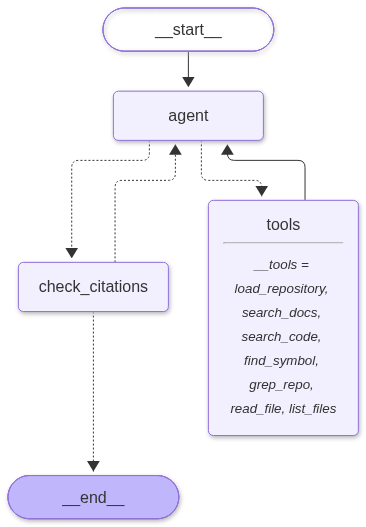

In [ ]:
# 9.1 Draw the agent graph (this is the LangGraph workflow the agent runs)
from IPython.display import Image, display

try:
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception as e:   # the PNG is rendered by the mermaid.ink web service
    print(f"(Couldn't render the picture: {e})\nMermaid source:\n")
    print(agent.get_graph().draw_mermaid())


## 10 · Run the agent from the notebook

In [ ]:
# 10 Run the agent

import time
import uuid
from IPython.display import Markdown, display
from langchain_core.messages import AIMessage, ToolMessage

THREAD = {"id": str(uuid.uuid4())}   # notebook conversation id

def new_conversation():
    """Start a fresh notebook conversation."""
    THREAD["id"] = str(uuid.uuid4())
    print("🧹 Started a new conversation.")

def _text(content) -> str:
    """Extract text from string or list-of-parts content."""
    if isinstance(content, str):
        return content
    return "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)

def _is_capacity_error(text: str) -> bool:
    return any(k in text for k in ("429", "503", "504", "DEADLINE", "UNAVAILABLE",
                                   "RESOURCE_EXHAUSTED", "quota", "imeout"))

# `path/to/file.py:12-34` (or just `path/to/file.py`) in an answer -> link to GitHub
CITATION_RE = re.compile(r"(?<!\[)`([\w./-]+\.[A-Za-z0-9]+)(?::(\d+)(?:-(\d+))?)?`")

def link_citations(text: str) -> str:
    """Turn file:line citations into GitHub links (only for files that really exist)."""
    if not STATE["url"]:
        return text
    def repl(m):
        path, start, end = m.group(1).lstrip("/"), m.group(2), m.group(3) or m.group(2)
        try:
            if not _safe_path(path).is_file():
                return m.group(0)
        except Exception:
            return m.group(0)
        anchor = f"#L{start}-L{end}" if start else ""
        return f"[{m.group(0)}]({STATE['url']}/blob/HEAD/{path}{anchor})"
    return CITATION_RE.sub(repl, text)

def agent_events(question: str, thread_id: str):
    """Run the agent on one question, yielding events:
        {"type": "tool_call",   "id", "name", "args"}
        {"type": "tool_result", "id", "name", "content"}
        {"type": "slow",        "seconds"}           (step took >30s)
        {"type": "check",       "text"}              (citation check result)
        {"type": "answer",      "text", "seconds"}   (last, on success)
        {"type": "error",       "text"}
    """
    message = f"[Active repository: {STATE['url']}]\n\n{question}" if STATE["url"] else question
    config = {"configurable": {"thread_id": thread_id}, "recursion_limit": AGENT_RECURSION_LIMIT}
    final_answer, started = "", time.time()
    last = started
    try:
        # Yields each model turn / tool run as it finishes
        for step in agent.stream({"messages": [{"role": "user", "content": message}],
                                  "tool_calls": 0, "revisions": 0, "check_note": ""},   # reset per question
                                 config=config, stream_mode="updates"):
            now = time.time()
            if now - last > 30:
                yield {"type": "slow", "seconds": round(now - last)}
            last = now
            for node, node_output in step.items():
                if node == "check_citations" and (node_output or {}).get("check_note"):
                    yield {"type": "check", "text": node_output["check_note"]}
                for msg in (node_output or {}).get("messages", []):
                    if isinstance(msg, AIMessage) and msg.tool_calls:
                        for call in msg.tool_calls:
                            yield {"type": "tool_call", "id": call.get("id"),
                                   "name": call["name"], "args": call["args"]}
                    elif isinstance(msg, ToolMessage):
                        yield {"type": "tool_result", "id": msg.tool_call_id, "name": msg.name,
                               "content": _text(msg.content)}
                    elif isinstance(msg, AIMessage):
                        final_answer = _text(msg.content)
    except Exception as e:
        text = f"{type(e).__name__}: {str(e)[:400]}"
        if _is_capacity_error(text):
            text += ("\n\nGemini is busy or rate-limiting you. Wait a minute and retry, "
                     "try another model, or enable billing in AI Studio.")
        yield {"type": "error", "text": text}
        return
    yield {"type": "answer", "seconds": round(time.time() - started),
           "text": link_citations(final_answer) if final_answer
                   else "_The agent returned no answer (try raising AGENT_RECURSION_LIMIT)._"}

def ask(question: str, repo_url: str | None = None, show_steps: bool = True) -> str:
    """Ask the agent a question, optionally loading repo_url first."""
    if repo_url:
        owner, repo = parse_github_url(repo_url)
        if STATE["namespace"] != repo_namespace(owner, repo):
            print(prepare_repository(repo_url), "\n")
            new_conversation()   # don't carry the previous repo's chat into this one
    answer = ""
    for event in agent_events(question, THREAD["id"]):
        if event["type"] == "tool_call" and show_steps:
            args = ", ".join(f"{k}={v!r}" for k, v in event["args"].items())
            print(f"🔧 {event['name']}({args})")
        elif event["type"] == "tool_result" and show_steps:
            print(f"   ↳ {event['content'].strip().replace(chr(10), ' ')[:150]}...")
        elif event["type"] == "slow" and show_steps:
            print(f"   ⏱️  that step took {event['seconds']}s (Gemini may be busy or rate-limiting you)")
        elif event["type"] == "check" and show_steps:
            print(f"🔎 citation check: {event['text']}")
        elif event["type"] == "error":
            print(f"\n❌ The agent stopped with an error: {event['text']}")
        elif event["type"] == "answer":
            answer = event["text"]
            print(f"\n(finished in {event['seconds']}s)\n" + "─" * 80)
            display(Markdown(answer))
    return answer



## 11 · Example questions

In [ ]:
# 11 Example question (assigned so Colab doesn't print the answer a second time)
answer = ask("Give me a high-level tour of this project: what it does and how the code is organized.",
             repo_url="https://github.com/pallets/itsdangerous")

Cloning https://github.com/pallets/itsdangerous ...
pallets/itsdangerous already indexed in Pinecone (105 vectors) — skipping embedding.
Repository pallets/itsdangerous is loaded and searchable.
Indexed: 9 documentation files, 9 Python files, 88 symbols.
Top-level contents: CHANGES.rst, LICENSE.txt, README.md, docs/, pyproject.toml, src/, tests/, uv.lock 

🧹 Started a new conversation.
🔧 load_repository(repo_url='https://github.com/pallets/itsdangerous')
   ↳ Repository pallets/itsdangerous is loaded and searchable. Indexed: 9 documentation files, 9 Python files, 88 symbols. Top-level contents: CHANGES.rst,...
🔧 search_docs(query='what is itsdangerous used for')
   ↳ ### README.md > ItsDangerous  [score 0.811] Document: README.md Section: ItsDangerous  # ItsDangerous   ... so better sign this   Various helpers to p...
🔧 list_files(directory='src/itsdangerous')
   ↳ __init__.py _json.py encoding.py exc.py py.typed serializer.py signer.py timed.py url_safe.py...
🔎 citation check: 🔁 sent 

The `itsdangerous` library is a set of utilities for cryptographically signing data so it can be safely passed to untrusted environments (like cookies or URLs) and verified later, ensuring the data has not been tampered with.

### Summary
The library is organized into two primary layers:
1.  **Signers ([`src/itsdangerous/signer.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/signer.py))**: The low-level interface that signs raw `bytes` using HMAC.
2.  **Serializers ([`src/itsdangerous/serializer.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/serializer.py))**: A higher-level interface that wraps signers to automatically convert Python objects to and from a signed string representation.

It is widely used by web frameworks like Flask for session management, user activation tokens, and email verification links.

### Walkthrough
If you were to implement a simple token, the flow looks like this:

1.  **Configuration**: You instantiate a serializer with a secret key. The `Serializer` class handles the heavy lifting of signing parameters and data serialization.
    *   [`src/itsdangerous/serializer.py:1-404`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/serializer.py#L1-L404): The `Serializer` class initializes the signing parameters and the underlying serializer (which defaults to using `json` for data conversion).
2.  **Signing (`dumps`)**:
    *   `serializer.dumps()` is called: It serializes your Python object to a string or bytes, then delegates the actual signing to the `Signer` class.
    *   [`src/itsdangerous/signer.py:15-100`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/signer.py#L15-L100): The `Signer` class computes an HMAC signature of the data using the `secret_key` and appends it to the original data (often separated by a period `.`).
3.  **Transmission**: You send the resulting signed string to the client (e.g., in a URL or cookie).
4.  **Verification (`loads`)**:
    *   `serializer.loads()` is called: It verifies the signature by recalculating the HMAC and comparing it to the signature in the token.
    *   [`src/itsdangerous/signer.py:100-266`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/signer.py#L100-L266): The `Signer.verify_signer` method performs the cryptographic check. It uses a constant-time comparison to prevent timing attacks.
    *   If invalid (tampered or expired), it raises an exception (defined in [`src/itsdangerous/exc.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/exc.py)).

### Key Files
A newcomer should start by exploring these files in `src/itsdangerous/`:

*   **[`src/itsdangerous/serializer.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/serializer.py)**: The primary user-facing class. Start here to understand how to serialize and sign data.
*   **[`src/itsdangerous/signer.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/signer.py)**: The core cryptographic logic. Read this if you need to understand how the HMAC signatures are constructed and verified.
*   **[`src/itsdangerous/timed.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/timed.py)**: An extension of the serializer that adds timestamping, which is critical for tokens that should expire (e.g., password reset tokens).
*   **[`src/itsdangerous/url_safe.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/url_safe.py)**: A specialized serializer configured to produce strings that are safe for use in URLs (using URL-safe base64 encoding).
*   **[`src/itsdangerous/exc.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/exc.py)**: Contains the exception hierarchy. Essential for handling cases where signature verification fails.

In [ ]:
# 11.1 Follow-up question (same conversation)
answer = ask("Walk me through deployment and use of this repo.")

🔧 search_docs(query='how to install and use itsdangerous')
   ↳ ### docs/index.rst > (top)  [score 0.791] Document: docs/index.rst Section: (top)  .. rst-class:: hide-header  ItsDangerous ============  .. image:: _...
🔎 citation check: 🔁 sent back for a rewrite: `requirements.txt` does not exist
🔧 read_file(end_line=20, path='pyproject.toml', start_line=1)
   ↳ pyproject.toml (lines 1-20 of 205)     1 | [project]     2 | name = "itsdangerous"     3 | version = "2.3.0.dev"     4 | description = "Safely pass da...
🔎 citation check: ✅ 7 citation(s) verified against the repository

(finished in 8s)
────────────────────────────────────────────────────────────────────────────────


Deploying and using `itsdangerous` is straightforward, as it is a library designed to be integrated into your application code.

### 1. Installation and Configuration
Because `itsdangerous` is a Python library, deployment involves including it in your project's dependencies and configuring your environment securely.

*   **Installation**: You can install the package using `pip`. The project metadata is defined in [`pyproject.toml:1-20`](https://github.com/pallets/itsdangerous/blob/HEAD/pyproject.toml#L1-L20).
    ```bash
    pip install itsdangerous
    ```
*   **Secret Key Management**: The security of your data relies entirely on your `secret_key`. This key should be a secure, random string.
    *   **Keep it secret**: Never commit the secret key to version control.
    *   **Use Environment Variables**: Load the key from an environment variable:
        ```python
        import os
        SECRET_KEY = os.environ.get("MY_APP_SECRET_KEY")
        ```
    *   **Key Rotation**: If you suspect a leak, change the secret key. Note that changing the key will immediately invalidate all existing tokens generated with the old key, as explained in [`docs/concepts.rst`](https://github.com/pallets/itsdangerous/blob/HEAD/docs/concepts.rst).

### 2. Basic Usage Pattern
The library provides abstractions for signing data. The most common entry point is the `Serializer` class, which handles the orchestration of signing and serialization.

#### A. Generating a Signed Token (`dumps`)
Use the `dumps` method to convert your data into a secure, signed string. The `Serializer` class logic is defined in [`src/itsdangerous/serializer.py:1-404`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/serializer.py#L1-L404).

```python
from itsdangerous import URLSafeSerializer

# Initialize with your secret key. The 'salt' argument helps distinguish 
# between different contexts (e.g., email verification vs session cookies).
s = URLSafeSerializer(SECRET_KEY, salt="email-verification")

# Sign data (can be a dict, list, string, etc.)
token = s.dumps({"user_id": 123, "action": "unsubscribe"})
# 'token' is now a URL-safe string.
```

#### B. Verifying a Token (`loads`)
When the token returns from the client, use `loads` to check the signature.

```python
try:
    data = s.loads(token)
    print(data["user_id"])  # 123
except itsdangerous.BadSignature:
    # This happens if the token was tampered with or the key is wrong.
    # Exception types are defined in src/itsdangerous/exc.py.
    print("Token is invalid!")
```

### 3. Key Concepts for Usage
*   **Signer vs. Serializer**: Use `Serializer` (and its subclasses in [`src/itsdangerous/serializer.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/serializer.py)) if you want to sign Python objects. Use `Signer` (defined in [`src/itsdangerous/signer.py:15-266`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/signer.py#L15-L266)) only if you are signing raw `bytes`.
*   **URL-Safe Tokens**: Most web applications use `URLSafeSerializer` to ensure that tokens do not contain characters that break URL structures.
*   **Timed Tokens**: If you need tokens to expire (e.g., a "reset password" link valid for 1 hour), use `URLSafeTimedSerializer` from [`src/itsdangerous/timed.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/timed.py):
    ```python
    from itsdangerous import URLSafeTimedSerializer
    s = URLSafeTimedSerializer(SECRET_KEY)
    token = s.dumps("data")

    # Verify and check age in seconds
    try:
        data = s.loads(token, max_age=3600)  # expires after 1 hour
    except itsdangerous.SignatureExpired:
        print("Token is too old!")
    ```
*   **Exception Handling**: Always wrap your `loads` call in a try/except block to handle `BadSignature` (tampering), `SignatureExpired` (if using `TimedSerializer`), or `BadData` (general errors). These are defined in [`src/itsdangerous/exc.py`](https://github.com/pallets/itsdangerous/blob/HEAD/src/itsdangerous/exc.py).

## 12 · Web UI (Gradio)

In [ ]:
# 12 Web UI (Gradio)

!pip install -q "gradio>=6,<7"


## 13 · Build the UI

In [ ]:
# 13 Build the UI
import json
import threading
import gradio as gr

# 13.1 Serialize access to the shared STATE
AGENT_LOCK = threading.Lock()

EMPTY_REPO = dict(url=None, owner=None, repo=None, path=None, namespace=None,
                  symbols=defaultdict(list), summary=None)

def _ensure_session(session: dict) -> dict:
    """Ensure the session has a thread_id and namespace."""
    session = dict(session or {})
    session.setdefault("namespace", None)
    if not session.get("thread_id"):
        session["thread_id"] = str(uuid.uuid4())
    return session

def _activate(session: dict):
    """Point STATE at this session's repository."""
    ns = session.get("namespace")
    STATE.update(REPO_CACHE[ns] if ns in REPO_CACHE else EMPTY_REPO)

def _status_text(session: dict) -> str:
    ns = session.get("namespace")
    if ns not in REPO_CACHE:
        return "**No repository loaded.** Paste a GitHub URL above and click **Load repository**."
    r = REPO_CACHE[ns]
    indexed = r["summary"].splitlines()[1] if r.get("summary") else ""
    return f"✅ **[{r['owner']}/{r['repo']}]({r['url']})** · {indexed} · model `{working_models[0][0]}`"

# 13.2 Event handlers
def ui_load_repo(repo_url, session, progress=gr.Progress()):
    """Load/index the repo and start a new conversation."""
    session = _ensure_session(session)
    if not (repo_url or "").strip():
        return session, "⚠️ Enter a GitHub repository URL first.", gr.update()
    with AGENT_LOCK:
        try:
            prepare_repository(repo_url, progress=lambda frac, msg: progress(frac, desc=msg))
        except Exception as e:
            return session, f"❌ Could not load the repository: {e}", gr.update()
        session.update(namespace=STATE["namespace"], thread_id=str(uuid.uuid4()))
    return session, _status_text(session), []          # [] clears the chat window

def ui_new_conversation(session):
    """Keep the repo, clear the chat history."""
    session = _ensure_session(session)
    session["thread_id"] = str(uuid.uuid4())
    return session, []

def ui_chat(message, history, session):
    """Stream tool calls and the answer into the chat; each yield updates the UI."""
    session = _ensure_session(session)
    history = list(history or [])
    message = (message or "").strip()
    if not message:
        yield history, "", session, _status_text(session)
        return
    history.append({"role": "user", "content": message})

    if session["namespace"] is None and "github.com" not in message:
        history.append({"role": "assistant", "content":
                        "Please load a repository first (box above), or include a GitHub URL in your question."})
        yield history, "", session, _status_text(session)
        return

    # Wait if another question is running
    if not AGENT_LOCK.acquire(blocking=False):
        history.append({"role": "assistant", "content": "⏳ Another question is running; waiting for my turn..."})
        yield history, "", session, _status_text(session)
        AGENT_LOCK.acquire()
        history.pop()
    try:
        _activate(session)
        yield history, "", session, _status_text(session)
        step_index = {}                                   # tool_call id -> history index
        for event in agent_events(message, session["thread_id"]):
            if event["type"] == "tool_call":
                args = ", ".join(f"{k}={v!r}" for k, v in event["args"].items())
                history.append({"role": "assistant", "content": "running...",
                                "metadata": {"title": f"🔧 {event['name']}({args[:120]})", "status": "pending"}})
                step_index[event["id"]] = len(history) - 1
            elif event["type"] == "tool_result":
                i = step_index.get(event["id"])
                result = event["content"].strip()
                result = result[:1500] + ("\n... (truncated)" if len(result) > 1500 else "")
                body = "```\n" + result.replace("```", "` ` `") + "\n```"
                if i is not None:
                    history[i] = {"role": "assistant", "content": body,
                                  "metadata": {**history[i]["metadata"], "status": "done"}}
                else:
                    history.append({"role": "assistant", "content": body,
                                    "metadata": {"title": f"🔧 {event['name']}", "status": "done"}})
            elif event["type"] == "check":
                history.append({"role": "assistant", "content": event["text"],
                                "metadata": {"title": "🔎 Citation check", "status": "done"}})
            elif event["type"] == "slow":
                history.append({"role": "assistant", "content":
                                f"⏱️ That step took {event['seconds']}s; Gemini may be busy."})
            elif event["type"] == "error":
                history.append({"role": "assistant", "content": f"❌ {event['text']}"})
            elif event["type"] == "answer":
                history.append({"role": "assistant",
                                "content": event["text"] + f"\n\n<sub>Answered in {event['seconds']}s</sub>"})
            yield history, "", session, _status_text(session)
        # Agent may have switched repos via load_repository
        session["namespace"] = STATE["namespace"]
        yield history, "", session, _status_text(session)
    finally:
        AGENT_LOCK.release()

# 13.3 Layout
with gr.Blocks(title="Codebase Onboarding Agent") as demo:
    session = gr.State({"thread_id": None, "namespace": None})   # per visitor
    gr.Markdown("# 🧭 Codebase Onboarding Agent\n"
                "Ask questions about any public **Python** GitHub repository. The agent searches "
                "the docs and code, follows the trail, and cites `file:line` for every claim.")
    with gr.Row():
        repo_box = gr.Textbox(label="GitHub repository", placeholder="https://github.com/owner/repo", scale=5)
        load_btn = gr.Button("Load repository", variant="primary", scale=1)
    status = gr.Markdown(_status_text({}))
    chatbot = gr.Chatbot(label="Conversation", height=560)
    with gr.Row():
        question_box = gr.Textbox(placeholder="e.g. How does signing work, step by step?",
                                  show_label=False, scale=5)
        ask_btn = gr.Button("Ask", variant="primary", scale=1)
    with gr.Row():
        new_btn = gr.Button("🧹 New conversation")
    gr.Examples(label="Example questions", inputs=question_box, examples=[
        ["Give me a high-level tour: what does this project do and how is the code organized?"],
        ["What are the main entry points a user of this library calls?"],
        ["Which files should a new contributor read first, and why?"],
        ["Where are errors and exceptions defined, and when are they raised?"],
    ])

    # Wire events
    load_btn.click(ui_load_repo, [repo_box, session], [session, status, chatbot])
    repo_box.submit(ui_load_repo, [repo_box, session], [session, status, chatbot])
    ask_btn.click(ui_chat, [question_box, chatbot, session], [chatbot, question_box, session, status])
    question_box.submit(ui_chat, [question_box, chatbot, session], [chatbot, question_box, session, status])
    new_btn.click(ui_new_conversation, [session], [session, chatbot])

print("✅ UI built. Run the next cell to launch it.")

✅ UI built. Run the next cell to launch it.


## 14 · Launch
Set the UI login secrets first.

In [ ]:
# 14 Launch (login required if UI_USERNAME/UI_PASSWORD are set)
auth = (UI_USERNAME, UI_PASSWORD) if UI_USERNAME and UI_PASSWORD else None
if auth is None:
    print("⚠️  No login set: anyone with the public link can use your API quota. "
          "Add UI_USERNAME and UI_PASSWORD as Colab Secrets, then rerun cells 1-2.")
demo.queue(default_concurrency_limit=4).launch(share=True, auth=auth)

⚠️  No login set: anyone with the public link can use your API quota. Add UI_USERNAME and UI_PASSWORD as Colab Secrets, then rerun cells 1-2.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f3b10f7c0cf8c6e6e8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15 · Utilities

In [ ]:
# 15 Utilities: manage indexed repos in Pinecone
def list_indexed_repositories():
    """Print each indexed repo namespace and its vector count."""
    namespaces = _field(pinecone_index.describe_index_stats(), "namespaces", {}) or {}
    if not namespaces:
        print("(nothing indexed yet)")
    for ns, info in namespaces.items():
        print(f"{ns:50s} {int(_field(info, 'vector_count', 0)):>6} vectors")

def reindex_repository(repo_url: str):
    """Delete and rebuild a repo's vectors (e.g. after chunking changes)."""
    owner, repo = parse_github_url(repo_url)
    import shutil
    shutil.rmtree(Path(CLONE_DIR) / f"{owner}__{repo}", ignore_errors=True)   # get a fresh clone
    REPO_CACHE.pop(repo_namespace(owner, repo), None)
    print(prepare_repository(repo_url, force_reindex=True))

def delete_repository_index(repo_url: str):
    """Remove a repo's vectors from Pinecone."""
    owner, repo = parse_github_url(repo_url)
    pinecone_index.delete(delete_all=True, namespace=repo_namespace(owner, repo))
    print(f"🗑️  Deleted vectors for {owner}/{repo}")

list_indexed_repositories()



nvidia--auto-ontology                                1050 vectors
pallets--itsdangerous                                 105 vectors


## 16 · Evaluation
Eight questions about `pallets/itsdangerous`. Takes several minutes on the free tier.

In [ ]:
# 16 Evaluation: does the agent cite the right files?
import contextlib
import uuid
import pandas as pd

RUN_EVAL = True            # set to False to skip (it takes several minutes on Gemini's free tier)
EVAL_REPO = "https://github.com/pallets/itsdangerous"
EVAL_PAUSE_SECONDS = 5     # breathing room between questions for the free-tier rate limits

# Each case: a question and the file(s) a correct answer must cite (citing any one counts).
# The last case is out of scope: the agent passes by saying the repo doesn't do that.
EVAL_SET = [
    {"question": "How does Signer create a signature, and how does it check one when unsigning?",
     "expect_any": ["src/itsdangerous/signer.py"]},
    {"question": "How do timestamps and max_age expiry work?",
     "expect_any": ["src/itsdangerous/timed.py"]},
    {"question": "Which exception is raised when a signature has expired, and where is it defined?",
     "expect_any": ["src/itsdangerous/exc.py"]},
    {"question": "How does Serializer.dumps turn a Python object into a signed string?",
     "expect_any": ["src/itsdangerous/serializer.py"]},
    {"question": "How does URLSafeSerializer make its output safe to put in a URL?",
     "expect_any": ["src/itsdangerous/url_safe.py", "src/itsdangerous/encoding.py"]},
    {"question": "Which key derivation options does Signer support, and which one is the default?",
     "expect_any": ["src/itsdangerous/signer.py"]},
    {"question": "Where is the URL-safe base64 encoding and decoding implemented?",
     "expect_any": ["src/itsdangerous/encoding.py"]},
    {"question": "How does itsdangerous save signed tokens to a PostgreSQL database?",
     "out_of_scope": True},
]
# Phrases that show the agent said the feature isn't in the repo (for the out-of-scope case)
NOT_IN_REPO_PHRASES = ("not in the repo", "isn't in the repo", "does not", "doesn't", "no code",
                       "not part of", "not found", "there is no", "no database", "not include")


def run_case(question: str) -> dict:
    """Ask one question in a fresh conversation; collect the answer, tool calls and check result."""
    for attempt in range(2):
        tools, note, answer, error, seconds = 0, "", "", "", 0
        for event in agent_events(question, str(uuid.uuid4())):
            if event["type"] == "tool_call":
                tools += 1
            elif event["type"] == "check":
                note = event["text"]
            elif event["type"] == "answer":
                answer, seconds = event["text"], event["seconds"]
            elif event["type"] == "error":
                error = event["text"]
        if not error:
            break
        print(f"   ⚠️ {error[:120]} (retrying in 30s)")
        time.sleep(30)
    return {"answer": answer, "tool_calls": tools, "check": note, "error": error, "seconds": seconds}


def grade(case: dict, result: dict) -> dict:
    answer = result["answer"]
    cited = sorted({path for path, _, _ in find_citations(answer)})
    problems, _ = citation_problems(answer)
    if case.get("out_of_scope"):
        right = any(p in answer.lower() for p in NOT_IN_REPO_PHRASES)
        expected = "says it's not in the repo"
    else:
        right = any(c == e or c.endswith("/" + e) for c in cited for e in case["expect_any"])
        expected = " or ".join(case["expect_any"])
    return {"question": case["question"], "pass": bool(right and not problems and not result["error"]),
            "expected": expected, "found_expected": right, "citations_valid": not problems,
            "files_cited": ", ".join(cited) or "(none)", "tool_calls": result["tool_calls"],
            "seconds": result["seconds"], "citation_check": result["check"],
            "problems": "; ".join(problems + ([result["error"]] if result["error"] else []))}


def run_eval(cases=EVAL_SET, repo_url=EVAL_REPO) -> pd.DataFrame:
    lock = globals().get("AGENT_LOCK")          # don't collide with someone using the web UI
    rows = []
    with (lock if lock else contextlib.nullcontext()):
        print(prepare_repository(repo_url), "\n")
        for n, case in enumerate(cases, 1):
            print(f"[{n}/{len(cases)}] {case['question']}")
            row = grade(case, run_case(case["question"]))
            rows.append(row)
            print(f"   {'✅ pass' if row['pass'] else '❌ fail'} · cited: {row['files_cited']} · "
                  f"{row['tool_calls']} tool calls · {row['seconds']}s")
            time.sleep(EVAL_PAUSE_SECONDS)
    return pd.DataFrame(rows)


if RUN_EVAL:
    df_eval = run_eval()
    df_eval.to_csv("eval_results.csv", index=False)
    print(f"\nScore: {df_eval['pass'].sum()}/{len(df_eval)} questions passed  ·  "
          f"citations valid in {df_eval['citations_valid'].sum()}/{len(df_eval)} answers  ·  "
          f"average {df_eval['tool_calls'].mean():.1f} tool calls and {df_eval['seconds'].mean():.0f}s per question")
    pd.set_option("display.max_colwidth", 120)
    display(df_eval[["question", "pass", "files_cited", "tool_calls", "seconds", "citation_check", "problems"]])
else:
    print("Evaluation skipped (RUN_EVAL = False).")


Repository pallets/itsdangerous is loaded and searchable.
Indexed: 9 documentation files, 9 Python files, 88 symbols.
Top-level contents: CHANGES.rst, LICENSE.txt, README.md, docs/, pyproject.toml, src/, tests/, uv.lock 

[1/8] How does Signer create a signature, and how does it check one when unsigning?
   ✅ pass · cited: src/itsdangerous/signer.py · 3 tool calls · 5s
[2/8] How do timestamps and max_age expiry work?
   ⚠️ GoogleRateLimitError: Error calling model 'gemini-3.1-flash-lite' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error' (retrying in 30s)
   ✅ pass · cited: src/itsdangerous/timed.py · 4 tool calls · 5s
[3/8] Which exception is raised when a signature has expired, and where is it defined?
   ✅ pass · cited: src/itsdangerous/__init__.py, src/itsdangerous/exc.py, src/itsdangerous/timed.py · 3 tool calls · 7s
[4/8] How does Serializer.dumps turn a Python object into a signed string?
   ✅ pass · cited: src/itsdangerous/serializer.py, src/itsdangerous/signer.py · 6 tool 

,question,pass,files_cited,tool_calls,seconds,citation_check,problems
0,"How does Signer create a signature, and how does it check one when unsigning?",True,src/itsdangerous/signer.py,3,5,✅ 6 citation(s) verified against the repository,
1,How do timestamps and max_age expiry work?,True,src/itsdangerous/timed.py,4,5,✅ 4 citation(s) verified against the repository,
2,"Which exception is raised when a signature has expired, and where is it defined?",True,"src/itsdangerous/__init__.py, src/itsdangerous/exc.py, src/itsdangerous/timed.py",3,7,✅ 6 citation(s) verified against the repository,
3,How does Serializer.dumps turn a Python object into a signed string?,True,"src/itsdangerous/serializer.py, src/itsdangerous/signer.py",6,9,✅ 6 citation(s) verified against the repository,
4,How does URLSafeSerializer make its output safe to put in a URL?,True,"src/itsdangerous/encoding.py, src/itsdangerous/url_safe.py",4,5,✅ 5 citation(s) verified against the repository,
5,"Which key derivation options does Signer support, and which one is the default?",True,src/itsdangerous/signer.py,3,3,✅ 3 citation(s) verified against the repository,
6,Where is the URL-safe base64 encoding and decoding implemented?,True,"src/itsdangerous/encoding.py, tests/test_itsdangerous/test_encoding.py",2,3,✅ 5 citation(s) verified against the repository,
7,How does itsdangerous save signed tokens to a PostgreSQL database?,True,"src/itsdangerous/serializer.py, src/itsdangerous/signer.py",2,4,✅ 2 citation(s) verified against the repository,
